In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# 13장 텐서플로를 사용한 데이터 적재와 전처리

## 13.1 데이터 API

In [2]:
X = tf.range(10)
dataset = tf.data.Dataset.from_tensor_slices(X)
dataset

<_TensorSliceDataset element_spec=TensorSpec(shape=(), dtype=tf.int32, name=None)>

In [3]:
for item in dataset:
    print(item)

tf.Tensor(0, shape=(), dtype=int32)
tf.Tensor(1, shape=(), dtype=int32)
tf.Tensor(2, shape=(), dtype=int32)
tf.Tensor(3, shape=(), dtype=int32)
tf.Tensor(4, shape=(), dtype=int32)
tf.Tensor(5, shape=(), dtype=int32)
tf.Tensor(6, shape=(), dtype=int32)
tf.Tensor(7, shape=(), dtype=int32)
tf.Tensor(8, shape=(), dtype=int32)
tf.Tensor(9, shape=(), dtype=int32)


In [4]:
X_nested = {'a': ([1, 2, 3], [4, 5, 6]), 'b': [7, 8, 9]}
dataset = tf.data.Dataset.from_tensor_slices(X_nested)
for item in dataset:
    print(item)

{'a': (<tf.Tensor: shape=(), dtype=int32, numpy=1>, <tf.Tensor: shape=(), dtype=int32, numpy=4>), 'b': <tf.Tensor: shape=(), dtype=int32, numpy=7>}
{'a': (<tf.Tensor: shape=(), dtype=int32, numpy=2>, <tf.Tensor: shape=(), dtype=int32, numpy=5>), 'b': <tf.Tensor: shape=(), dtype=int32, numpy=8>}
{'a': (<tf.Tensor: shape=(), dtype=int32, numpy=3>, <tf.Tensor: shape=(), dtype=int32, numpy=6>), 'b': <tf.Tensor: shape=(), dtype=int32, numpy=9>}


### 13.1.1 연쇄 변환

In [5]:
dataset = tf.data.Dataset.from_tensor_slices(X)
dataset = dataset.repeat(3).batch(7)
for item in dataset:
    print(item)

tf.Tensor([0 1 2 3 4 5 6], shape=(7,), dtype=int32)
tf.Tensor([7 8 9 0 1 2 3], shape=(7,), dtype=int32)
tf.Tensor([4 5 6 7 8 9 0], shape=(7,), dtype=int32)
tf.Tensor([1 2 3 4 5 6 7], shape=(7,), dtype=int32)
tf.Tensor([8 9], shape=(2,), dtype=int32)


In [6]:
dataset = tf.data.Dataset.from_tensor_slices(X)
dataset = dataset.repeat(3).batch(7, drop_remainder=True)
for item in dataset:
    print(item)

tf.Tensor([0 1 2 3 4 5 6], shape=(7,), dtype=int32)
tf.Tensor([7 8 9 0 1 2 3], shape=(7,), dtype=int32)
tf.Tensor([4 5 6 7 8 9 0], shape=(7,), dtype=int32)
tf.Tensor([1 2 3 4 5 6 7], shape=(7,), dtype=int32)


In [7]:
dataset = dataset.map(lambda x: x * 2)
for item in dataset:
    print(item)

tf.Tensor([ 0  2  4  6  8 10 12], shape=(7,), dtype=int32)
tf.Tensor([14 16 18  0  2  4  6], shape=(7,), dtype=int32)
tf.Tensor([ 8 10 12 14 16 18  0], shape=(7,), dtype=int32)
tf.Tensor([ 2  4  6  8 10 12 14], shape=(7,), dtype=int32)


In [8]:
dataset = dataset.filter(lambda x: tf.reduce_sum(x) > 50)
for item in dataset:
    print(item)

tf.Tensor([14 16 18  0  2  4  6], shape=(7,), dtype=int32)
tf.Tensor([ 8 10 12 14 16 18  0], shape=(7,), dtype=int32)
tf.Tensor([ 2  4  6  8 10 12 14], shape=(7,), dtype=int32)


In [9]:
for item in dataset.take(2):
    print(item)

tf.Tensor([14 16 18  0  2  4  6], shape=(7,), dtype=int32)
tf.Tensor([ 8 10 12 14 16 18  0], shape=(7,), dtype=int32)


### 13.1.2 데이터 셔플링

In [10]:
dataset = tf.data.Dataset.range(10).repeat(2)
dataset = dataset.shuffle(buffer_size=4, seed=42).batch(7)
for item in dataset:
    print(item)

tf.Tensor([1 4 2 3 5 0 6], shape=(7,), dtype=int64)
tf.Tensor([9 8 2 0 3 1 4], shape=(7,), dtype=int64)
tf.Tensor([5 7 9 6 7 8], shape=(6,), dtype=int64)


In [11]:
dataset = tf.data.Dataset.range(10)
dataset = dataset.shuffle(buffer_size=4, seed=42).repeat(2).batch(7)
for item in dataset:
    print(item)

tf.Tensor([1 4 2 3 5 0 6], shape=(7,), dtype=int64)
tf.Tensor([8 7 9 3 4 2 0], shape=(7,), dtype=int64)
tf.Tensor([1 8 5 7 9 6], shape=(6,), dtype=int64)


### 13.1.3 여러 파일에서 한 줄씩 번가랑 읽기

In [12]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

housing = fetch_california_housing()
X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data, housing.target.reshape(-1, 1), random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42)

In [13]:
from pathlib import Path

def save_to_csv_files(data, name_prefix, header=None, n_parts=10):
    housing_dir = Path() / 'datasets' / 'housing'
    housing_dir.mkdir(parents=True, exist_ok=True)
    filename_format = 'my_{}_{:02d}.csv'

    filepaths = []
    m = len(data)
    chunks = np.array_split(np.arange(m), n_parts)
    for file_idx, row_indices in enumerate(chunks):
        part_csv = housing_dir / filename_format.format(name_prefix, file_idx)
        filepaths.append(str(part_csv))
        with open(part_csv, 'w') as f:
            if header is not None:
                f.write(header)
                f.write('\n')
            for row_idx in row_indices:
                f.write(','.join([str(col) for col in data[row_idx]]))
                f.write('\n')
    return filepaths

train_data = np.c_[X_train, y_train]
valid_data = np.c_[X_valid, y_valid]
test_data = np.c_[X_test, y_test]
header_cols = housing.feature_names + ['MedianHouseValue']
header = ','.join(header_cols)

train_filepaths = save_to_csv_files(train_data, 'train', header, n_parts=20)
valid_filepaths = save_to_csv_files(valid_data, 'valid', header, n_parts=10)
test_filepaths = save_to_csv_files(test_data, 'test', header, n_parts=10)

In [14]:
print(''.join(open(train_filepaths[0]).readlines()[:4]))

MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedianHouseValue
3.5214,15.0,3.0499445061043287,1.106548279689234,1447.0,1.6059933407325193,37.63,-122.43,1.442
5.3275,5.0,6.490059642147117,0.9910536779324056,3464.0,3.4433399602385686,33.69,-117.39,1.687
3.1,29.0,7.5423728813559325,1.5915254237288134,1328.0,2.2508474576271187,38.44,-122.98,1.621



In [15]:
train_filepaths

['datasets/housing/my_train_00.csv',
 'datasets/housing/my_train_01.csv',
 'datasets/housing/my_train_02.csv',
 'datasets/housing/my_train_03.csv',
 'datasets/housing/my_train_04.csv',
 'datasets/housing/my_train_05.csv',
 'datasets/housing/my_train_06.csv',
 'datasets/housing/my_train_07.csv',
 'datasets/housing/my_train_08.csv',
 'datasets/housing/my_train_09.csv',
 'datasets/housing/my_train_10.csv',
 'datasets/housing/my_train_11.csv',
 'datasets/housing/my_train_12.csv',
 'datasets/housing/my_train_13.csv',
 'datasets/housing/my_train_14.csv',
 'datasets/housing/my_train_15.csv',
 'datasets/housing/my_train_16.csv',
 'datasets/housing/my_train_17.csv',
 'datasets/housing/my_train_18.csv',
 'datasets/housing/my_train_19.csv']

In [16]:
filepath_dataset = tf.data.Dataset.list_files(train_filepaths, seed=42)

for filepath in filepath_dataset:
    print(filepath)

tf.Tensor(b'datasets/housing/my_train_05.csv', shape=(), dtype=string)
tf.Tensor(b'datasets/housing/my_train_16.csv', shape=(), dtype=string)
tf.Tensor(b'datasets/housing/my_train_01.csv', shape=(), dtype=string)
tf.Tensor(b'datasets/housing/my_train_17.csv', shape=(), dtype=string)
tf.Tensor(b'datasets/housing/my_train_00.csv', shape=(), dtype=string)
tf.Tensor(b'datasets/housing/my_train_14.csv', shape=(), dtype=string)
tf.Tensor(b'datasets/housing/my_train_10.csv', shape=(), dtype=string)
tf.Tensor(b'datasets/housing/my_train_02.csv', shape=(), dtype=string)
tf.Tensor(b'datasets/housing/my_train_12.csv', shape=(), dtype=string)
tf.Tensor(b'datasets/housing/my_train_19.csv', shape=(), dtype=string)
tf.Tensor(b'datasets/housing/my_train_07.csv', shape=(), dtype=string)
tf.Tensor(b'datasets/housing/my_train_09.csv', shape=(), dtype=string)
tf.Tensor(b'datasets/housing/my_train_13.csv', shape=(), dtype=string)
tf.Tensor(b'datasets/housing/my_train_15.csv', shape=(), dtype=string)
tf.Ten

In [17]:
n_readers = 5
dataset = filepath_dataset.interleave(
    lambda filepath: tf.data.TextLineDataset(filepath).skip(1),
    cycle_length=n_readers
)

In [18]:
for line in dataset.take(5):
    print(line)

tf.Tensor(b'4.5909,16.0,5.475877192982456,1.0964912280701755,1357.0,2.9758771929824563,33.63,-117.71,2.418', shape=(), dtype=string)
tf.Tensor(b'2.4792,24.0,3.4547038327526134,1.1341463414634145,2251.0,3.921602787456446,34.18,-118.38,2.0', shape=(), dtype=string)
tf.Tensor(b'4.2708,45.0,5.121387283236994,0.953757225433526,492.0,2.8439306358381504,37.48,-122.19,2.67', shape=(), dtype=string)
tf.Tensor(b'2.1856,41.0,3.7189873417721517,1.0658227848101265,803.0,2.0329113924050635,32.76,-117.12,1.205', shape=(), dtype=string)
tf.Tensor(b'4.1812,52.0,5.701388888888889,0.9965277777777778,692.0,2.4027777777777777,33.73,-118.31,3.215', shape=(), dtype=string)


### 13.1.4 데이터 전처리

In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)

StandardScaler()

In [20]:
X_mean, X_std = scaler.mean_, scaler.scale_
n_inputs = 8

def parse_csv_line(line):
    defs = [0.] * n_inputs + [tf.constant([], dtype=tf.float32)]
    fields = tf.io.decode_csv(line, record_defaults=defs)
    return tf.stack(fields[:-1]), tf.stack(fields[-1:])

def preprocess(line):
    x, y = parse_csv_line(line)
    return (x - X_mean) / X_std, y

In [21]:
[0.] * n_inputs + [tf.constant([], dtype=tf.float32)]

[0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 <tf.Tensor: shape=(0,), dtype=float32, numpy=array([], dtype=float32)>]

In [22]:
preprocess(next(iter(dataset)))

(<tf.Tensor: shape=(8,), dtype=float32, numpy=
 array([-0.8936168 ,  0.9789995 , -0.6810549 , -0.07264194, -0.5669866 ,
        -0.39212456, -1.3522334 ,  1.2316071 ], dtype=float32)>,
 <tf.Tensor: shape=(1,), dtype=float32, numpy=array([1.205], dtype=float32)>)

### 13.1.5 데이터 적재와 전처리 합치기

In [23]:
def csv_reader_dataset(filepaths, n_readers=5, n_read_threads=None,
                      n_parse_threads=5, shuffle_buffer_size=10_000, seed=42,
                      batch_size=32):
    dataset = tf.data.Dataset.list_files(filepaths, seed=seed)
    dataset = dataset.interleave(
        lambda filepath: tf.data.TextLineDataset(filepath).skip(1),
        cycle_length=n_readers, num_parallel_calls=n_read_threads)
    dataset = dataset.map(preprocess, num_parallel_calls=n_parse_threads)
    dataset = dataset.shuffle(shuffle_buffer_size, seed=seed)
    return dataset.batch(batch_size).prefetch(1)

In [24]:
example_set = csv_reader_dataset(train_filepaths, batch_size=3)
for X_batch, y_batch in example_set.take(2):
    print('X =', X_batch)
    print('y =', y_batch)
    print()

X = tf.Tensor(
[[-1.3957452  -0.04940685 -0.22830808  0.22648273  2.2593622   0.35200632
   0.9667386  -1.4121602 ]
 [ 2.7112627  -1.0778131   0.69413143 -0.14870553  0.51810503  0.3507294
  -0.82285154  0.80680597]
 [-0.13484643 -1.868895    0.01032507 -0.13787179 -0.12893449  0.03143518
   0.2687057   0.13212144]], shape=(3, 8), dtype=float32)
y = tf.Tensor(
[[1.819]
 [3.674]
 [0.954]], shape=(3, 1), dtype=float32)

X = tf.Tensor(
[[ 0.09031774  0.9789995   0.1327582  -0.13753782 -0.23388447  0.10211545
   0.97610843 -1.4121602 ]
 [ 0.05218809 -2.0271113   0.2940109  -0.02403445  0.16218767 -0.02844518
   1.4117942  -0.93737936]
 [-0.672276    0.02970133 -0.76922584 -0.15086786  0.4962024  -0.02741998
  -0.7853724   0.77182245]], shape=(3, 8), dtype=float32)
y = tf.Tensor(
[[2.725]
 [1.205]
 [1.625]], shape=(3, 1), dtype=float32)



### 13.1.7 케라스와 데이터셋 사용하기

In [25]:
train_set = csv_reader_dataset(train_filepaths)
valid_set = csv_reader_dataset(valid_filepaths)
test_set = csv_reader_dataset(test_filepaths)

In [26]:
tf.keras.utils.set_random_seed(42)
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=X_train.shape[1:]),
    tf.keras.layers.Dense(30, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.Dense(1)
])
model.compile(loss='mse', optimizer='sgd')
model.fit(train_set, validation_data=valid_set, epochs=5)

Epoch 1/5
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 597us/step - loss: 1.0495 - val_loss: 692.2764
Epoch 2/5
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 576us/step - loss: 2.6754 - val_loss: 5.6114
Epoch 3/5
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 511us/step - loss: 0.5452 - val_loss: 140.3738
Epoch 4/5
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 494us/step - loss: 0.5171 - val_loss: 0.5109
Epoch 5/5
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 507us/step - loss: 0.4528 - val_loss: 1.3730


In [27]:
model.evaluate(test_set)

162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 313us/step - loss: 0.4171


0.41713592410087585

In [28]:
model.predict(test_set.take(1)).shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


(32, 1)

In [29]:
optimizer = tf.keras.optimizers.SGD(learning_rate=0.01)
loss_fn = tf.keras.losses.MeanSquaredError()

n_epochs = 5
for epoch in range(n_epochs):
    print(f'Epoch {epoch + 1}/{n_epochs}')
    for X_batch, y_batch in train_set:
        with tf.GradientTape() as tape:
            y_pred = model(X_batch)
            main_loss = tf.reduce_mean(loss_fn(y_batch, y_pred))
            loss = tf.add_n([main_loss] + model.losses)
        gradients = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))

Epoch 1/5
Epoch 2/5
Epoch 3/5
Epoch 4/5
Epoch 5/5


In [30]:
@tf.function
def train_one_epoch(model, optimizer, loss_fn, train_set):
    for X_batch, y_batch in train_set:
        with tf.GradientTape() as tape:
            y_pred = model(X_batch)
            main_loss = tf.reduce_mean(loss_fn(y_batch, y_pred))
            loss = tf.add_n([main_loss] + model.losses)
        gradients = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))

for epoch in range(n_epochs):
    print(f'Epoch {epoch + 1}/{n_epochs}')
    train_one_epoch(model, optimizer, loss_fn, train_set)

Epoch 1/5
Epoch 2/5
Epoch 3/5
Epoch 4/5
Epoch 5/5


## 13.2 TFRecord 포맷

In [31]:
with tf.io.TFRecordWriter('my_data.tfrecord') as f:
    f.write(b'This is the first record')
    f.write(b'And this is the second record')

In [32]:
filepaths = ['my_data.tfrecord']
dataset = tf.data.TFRecordDataset(filepaths)
for item in dataset:
    print(item)

tf.Tensor(b'This is the first record', shape=(), dtype=string)
tf.Tensor(b'And this is the second record', shape=(), dtype=string)


### 13.2.1 압축된 TFRecord 파일

In [33]:
options = tf.io.TFRecordOptions(compression_type='GZIP')
with tf.io.TFRecordWriter('my_compressed.tfrecord', options) as f:
    f.write(b'This is the first record')
    f.write(b'And this is the second record')

In [34]:
dataset = tf.data.TFRecordDataset(['my_compressed.tfrecord'],
                                  compression_type='GZIP')
for item in dataset:
    print(item)

tf.Tensor(b'This is the first record', shape=(), dtype=string)
tf.Tensor(b'And this is the second record', shape=(), dtype=string)


### 13.2.2 프로토콜 버퍼 개요

In [35]:
%%writefile person.proto
syntax = 'proto3';
message Person {
    string name = 1;
    int32 id = 2;
    repeated string email = 3;
}

Overwriting person.proto


In [36]:
!protoc person.proto --python_out=. --descriptor_set_out=person.desc --include_imports

In [37]:
from person_pb2 import Person

person = Person(name='Al', id=123, email=['user@example.com'])
person

name: "Al"
id: 123
email: "user@example.com"

In [38]:
person.name

'Al'

In [39]:
person.name = 'Alice'
person

name: "Alice"
id: 123
email: "user@example.com"

In [40]:
person.email[0]

'user@example.com'

In [41]:
person.email.append('user@example.net')
person

name: "Alice"
id: 123
email: "user@example.com"
email: "user@example.net"

In [42]:
serialized = person.SerializeToString()
serialized

b'\n\x05Alice\x10{\x1a\x10user@example.com\x1a\x10user@example.net'

In [43]:
person2 = Person()
person2.ParseFromString(serialized)

person == person2

True

In [44]:
person_tf = tf.io.decode_proto(
    bytes=serialized,
    message_type='Person',
    field_names=['name', 'id', 'email'],
    output_types=[tf.string, tf.int32, tf.string],
    descriptor_source='person.desc'
)

person_tf.values

[<tf.Tensor: shape=(1,), dtype=string, numpy=array([b'Alice'], dtype=object)>,
 <tf.Tensor: shape=(1,), dtype=int32, numpy=array([123], dtype=int32)>,
 <tf.Tensor: shape=(2,), dtype=string, numpy=array([b'user@example.com', b'user@example.net'], dtype=object)>]

### 13.2.3 텐서플로 프로토콜 버퍼

```protobuf
syntax = 'proto3';

message BytesList { repeated bytes value = 1; }
message FloatList { repeated float value = 1 [packed = true]; }
message Int64List { repeated int64 value = 1 [packed = true]; }
message Feature {
    oneof kind {
        BytesList bytes_list = 1;
        FloatList float_list = 2;
        Int64List int64_list = 3;
    }
};
message Features { map<string, Feature> feature = 1; };
message Example { Features features = 1; };
```

In [45]:
from tensorflow.train import BytesList, FloatList, Int64List
from tensorflow.train import Feature, Features, Example

person_example = Example(
    features=Features(
        feature={
            'name': Feature(bytes_list=BytesList(value=[b'Alice'])),
            'id': Feature(int64_list=Int64List(value=[123])),
            'emails': Feature(bytes_list=BytesList(value=[b'user@example.com', b'user@example.net']))
        }       
    )
)

In [46]:
with tf.io.TFRecordWriter('my_contacts.tfrecord') as f:
    for _ in range(5):
        f.write(person_example.SerializeToString())

### 13.2.4 Example 프로토콜 버퍼 읽고 파싱하기

In [47]:
feature_description = {
    'name': tf.io.FixedLenFeature([], tf.string, default_value=''),
    'id': tf.io.FixedLenFeature([], tf.int64, default_value=0),
    'emails': tf.io.VarLenFeature(tf.string)
}

def parse(serialized_example):
    return tf.io.parse_single_example(serialized_example, feature_description)

dataset = tf.data.TFRecordDataset(['my_contacts.tfrecord']).map(parse)
for parsed_example in dataset:
    print(parsed_example)

{'emails': SparseTensor(indices=tf.Tensor(
[[0]
 [1]], shape=(2, 1), dtype=int64), values=tf.Tensor([b'user@example.com' b'user@example.net'], shape=(2,), dtype=string), dense_shape=tf.Tensor([2], shape=(1,), dtype=int64)), 'id': <tf.Tensor: shape=(), dtype=int64, numpy=123>, 'name': <tf.Tensor: shape=(), dtype=string, numpy=b'Alice'>}
{'emails': SparseTensor(indices=tf.Tensor(
[[0]
 [1]], shape=(2, 1), dtype=int64), values=tf.Tensor([b'user@example.com' b'user@example.net'], shape=(2,), dtype=string), dense_shape=tf.Tensor([2], shape=(1,), dtype=int64)), 'id': <tf.Tensor: shape=(), dtype=int64, numpy=123>, 'name': <tf.Tensor: shape=(), dtype=string, numpy=b'Alice'>}
{'emails': SparseTensor(indices=tf.Tensor(
[[0]
 [1]], shape=(2, 1), dtype=int64), values=tf.Tensor([b'user@example.com' b'user@example.net'], shape=(2,), dtype=string), dense_shape=tf.Tensor([2], shape=(1,), dtype=int64)), 'id': <tf.Tensor: shape=(), dtype=int64, numpy=123>, 'name': <tf.Tensor: shape=(), dtype=string, num

In [48]:
tf.sparse.to_dense(parsed_example['emails'], default_value=b'')

<tf.Tensor: shape=(2,), dtype=string, numpy=array([b'user@example.com', b'user@example.net'], dtype=object)>

In [49]:
parsed_example['emails'].values

<tf.Tensor: shape=(2,), dtype=string, numpy=array([b'user@example.com', b'user@example.net'], dtype=object)>

In [50]:
def parse(serialized_examples):
    return tf.io.parse_example(serialized_examples, feature_description)

dataset = tf.data.TFRecordDataset(['my_contacts.tfrecord']).batch(2).map(parse)
for parsed_examples in dataset:
    print(parsed_examples)

{'emails': SparseTensor(indices=tf.Tensor(
[[0 0]
 [0 1]
 [1 0]
 [1 1]], shape=(4, 2), dtype=int64), values=tf.Tensor(
[b'user@example.com' b'user@example.net' b'user@example.com'
 b'user@example.net'], shape=(4,), dtype=string), dense_shape=tf.Tensor([2 2], shape=(2,), dtype=int64)), 'id': <tf.Tensor: shape=(2,), dtype=int64, numpy=array([123, 123])>, 'name': <tf.Tensor: shape=(2,), dtype=string, numpy=array([b'Alice', b'Alice'], dtype=object)>}
{'emails': SparseTensor(indices=tf.Tensor(
[[0 0]
 [0 1]
 [1 0]
 [1 1]], shape=(4, 2), dtype=int64), values=tf.Tensor(
[b'user@example.com' b'user@example.net' b'user@example.com'
 b'user@example.net'], shape=(4,), dtype=string), dense_shape=tf.Tensor([2 2], shape=(2,), dtype=int64)), 'id': <tf.Tensor: shape=(2,), dtype=int64, numpy=array([123, 123])>, 'name': <tf.Tensor: shape=(2,), dtype=string, numpy=array([b'Alice', b'Alice'], dtype=object)>}
{'emails': SparseTensor(indices=tf.Tensor(
[[0 0]
 [0 1]], shape=(2, 2), dtype=int64), values=tf.T

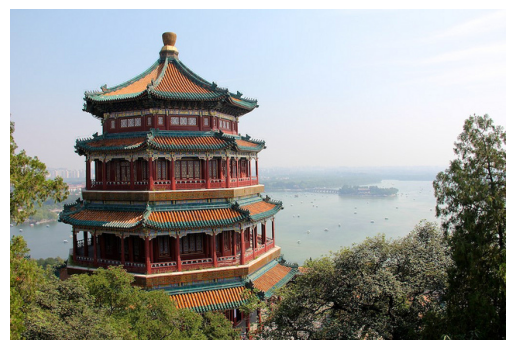

In [51]:
from sklearn.datasets import load_sample_images

img = load_sample_images()['images'][0]
plt.imshow(img)
plt.axis('off')
plt.show()

In [52]:
data = tf.io.encode_jpeg(img)

image_example = Example(
    features=Features(
        feature={
            'image': Feature(bytes_list=BytesList(value=[data.numpy()]))
        }
    )
)

serialized_example = image_example.SerializeToString()
with tf.io.TFRecordWriter('my_image.tfrecord') as f:
    f.write(serialized_example)

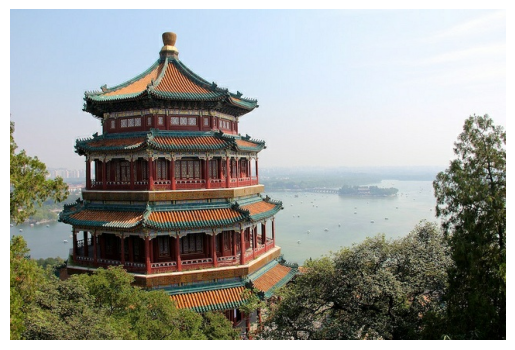

In [53]:
feature_description = {'image': tf.io.VarLenFeature(tf.string)}

def parse(serialized_example):
    example_image = tf.io.parse_example(serialized_example, feature_description)
    return tf.io.decode_jpeg(example_image['image'].values[0])

dataset = tf.data.TFRecordDataset(['my_image.tfrecord']).map(parse)
for image in dataset:
    plt.imshow(image)
    plt.axis('off')
    plt.show()

In [54]:
tensor = tf.constant([[1., 2.], [3., 4.], [5., 6.]])
serialized = tf.io.serialize_tensor(tensor)

serialized

<tf.Tensor: shape=(), dtype=string, numpy=b'\x08\x01\x12\x08\x12\x02\x08\x03\x12\x02\x08\x02"\x18\x00\x00\x80?\x00\x00\x00@\x00\x00@@\x00\x00\x80@\x00\x00\xa0@\x00\x00\xc0@'>

In [55]:
tf.io.parse_tensor(serialized, out_type=tf.float32)

<tf.Tensor: shape=(3, 2), dtype=float32, numpy=
array([[1., 2.],
       [3., 4.],
       [5., 6.]], dtype=float32)>

### 13.2.5 SequenceExample 프로토콜 버퍼로 리스트의 리스트 다루기

```protobuf
syntax 'proto3'
message FeatureList { repeated Feature feature = 1; };
message FeatureLists { map<string, FeatureLIst> feature_list = 1; };
message SequenceExample {
    Features context = 1;
    FeatureLists feature_lists = 2;
};
```

In [56]:
from tensorflow.train import FeatureList, FeatureLists, SequenceExample

context = Features(feature={
    'author_id': Feature(int64_list=Int64List(value=[123])),
    'title': Feature(bytes_list=BytesList(value=[b'A', b'desert', b'place', b'.'])),
    'pub_date': Feature(int64_list=Int64List(value=[1623, 12, 25]))
})

content = [['When', 'shall', 'we', 'three', 'meet', 'again', '?'],
           ['In', 'thunder', ',', 'lightning', ',', 'or', 'in', 'rain', '?']]
comments = [['When', 'the', 'hurlyburly', '\'s', 'done', '.'],
            ['When', 'the', 'battle', '\'s', 'lost', 'and', 'won', '.']]

def words_to_feature(words):
    return Feature(bytes_list=BytesList(value=[word.encode('utf-8') for word in words]))

content_features = [words_to_feature(sentence) for sentence in content]
comments_features = [words_to_feature(comment) for comment in comments]

sequence_example = SequenceExample(
    context=context,
    feature_lists=FeatureLists(feature_list={
        'content': FeatureList(feature=content_features),
        'comments': FeatureList(feature=comments_features)
    })
)

In [57]:
sequence_example

context {
  feature {
    key: "title"
    value {
      bytes_list {
        value: "A"
        value: "desert"
        value: "place"
        value: "."
      }
    }
  }
  feature {
    key: "pub_date"
    value {
      int64_list {
        value: 1623
        value: 12
        value: 25
      }
    }
  }
  feature {
    key: "author_id"
    value {
      int64_list {
        value: 123
      }
    }
  }
}
feature_lists {
  feature_list {
    key: "content"
    value {
      feature {
        bytes_list {
          value: "When"
          value: "shall"
          value: "we"
          value: "three"
          value: "meet"
          value: "again"
          value: "?"
        }
      }
      feature {
        bytes_list {
          value: "In"
          value: "thunder"
          value: ","
          value: "lightning"
          value: ","
          value: "or"
          value: "in"
          value: "rain"
          value: "?"
        }
      }
    }
  }
  feature_list {
    key: "c

In [58]:
serialized_sequence_example = sequence_example.SerializeToString()
serialized_sequence_example

b"\nL\n\x14\n\x08pub_date\x12\x08\x1a\x06\n\x04\xd7\x0c\x0c\x19\n\x12\n\tauthor_id\x12\x05\x1a\x03\n\x01{\n \n\x05title\x12\x17\n\x15\n\x01A\n\x06desert\n\x05place\n\x01.\x12\xd0\x01\nj\n\x07content\x12_\n*\n(\n\x04When\n\x05shall\n\x02we\n\x05three\n\x04meet\n\x05again\n\x01?\n1\n/\n\x02In\n\x07thunder\n\x01,\n\tlightning\n\x01,\n\x02or\n\x02in\n\x04rain\n\x01?\nb\n\x08comments\x12V\n&\n$\n\x04When\n\x03the\n\nhurlyburly\n\x02's\n\x04done\n\x01.\n,\n*\n\x04When\n\x03the\n\x06battle\n\x02's\n\x04lost\n\x03and\n\x03won\n\x01."

In [59]:
context_feature_descriptions = {
    'author_id': tf.io.FixedLenFeature([], tf.int64, default_value=0),
    'title': tf.io.VarLenFeature(tf.string),
    'pub_date': tf.io.FixedLenFeature([3], tf.int64, default_value=[0, 0, 0]),
}
sequence_feature_descriptions = {
    'content': tf.io.VarLenFeature(tf.string),
    'comments': tf.io.VarLenFeature(tf.string),
}

In [60]:
parsed_context, parsed_feature_lists = tf.io.parse_single_sequence_example(
    serialized_sequence_example, context_feature_descriptions, sequence_feature_descriptions)

In [61]:
parsed_feature_lists['content']

SparseTensor(indices=tf.Tensor(
[[0 0]
 [0 1]
 [0 2]
 [0 3]
 [0 4]
 [0 5]
 [0 6]
 [1 0]
 [1 1]
 [1 2]
 [1 3]
 [1 4]
 [1 5]
 [1 6]
 [1 7]
 [1 8]], shape=(16, 2), dtype=int64), values=tf.Tensor(
[b'When' b'shall' b'we' b'three' b'meet' b'again' b'?' b'In' b'thunder'
 b',' b'lightning' b',' b'or' b'in' b'rain' b'?'], shape=(16,), dtype=string), dense_shape=tf.Tensor([2 9], shape=(2,), dtype=int64))

In [62]:
parsed_feature_lists['content'].values

<tf.Tensor: shape=(16,), dtype=string, numpy=
array([b'When', b'shall', b'we', b'three', b'meet', b'again', b'?', b'In',
       b'thunder', b',', b'lightning', b',', b'or', b'in', b'rain', b'?'],
      dtype=object)>

In [63]:
tf.RaggedTensor.from_sparse(parsed_feature_lists['content'])

<tf.RaggedTensor [[b'When', b'shall', b'we', b'three', b'meet', b'again', b'?'],
 [b'In', b'thunder', b',', b'lightning', b',', b'or', b'in', b'rain', b'?']]>

In [64]:
parsed_context['title'].values

<tf.Tensor: shape=(4,), dtype=string, numpy=array([b'A', b'desert', b'place', b'.'], dtype=object)>

## 13.3 케라스의 전처리 층

### 13.3.1 Normalization 층

In [65]:
tf.random.set_seed(42)

norm_layer = tf.keras.layers.Normalization()
model = tf.keras.models.Sequential([
    norm_layer,
    tf.keras.layers.Dense(1)
])
norm_layer.adapt(X_train)

model.compile(loss='mse', optimizer=tf.keras.optimizers.SGD(learning_rate=2e-3))
history = model.fit(X_train, y_train, validation_data=(X_valid, y_valid), epochs=5)

Epoch 1/5
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 533us/step - loss: 2.4287 - val_loss: 1.6242
Epoch 2/5
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 409us/step - loss: 0.6855 - val_loss: 0.6081
Epoch 3/5
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 406us/step - loss: 0.5841 - val_loss: 0.6522
Epoch 4/5
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 651us/step - loss: 0.5700 - val_loss: 0.6388
Epoch 5/5
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 408us/step - loss: 0.5621 - val_loss: 0.6315


In [66]:
norm_layer = tf.keras.layers.Normalization()
norm_layer.adapt(X_train)
X_train_scaled = norm_layer(X_train)
X_valid_scaled = norm_layer(X_valid)

In [67]:
tf.random.set_seed(42)

model = tf.keras.models.Sequential([tf.keras.layers.Dense(1)])
model.compile(loss='mse', optimizer=tf.keras.optimizers.SGD(learning_rate=2e-3))
history = model.fit(X_train_scaled, y_train, validation_data=(X_valid_scaled, y_valid), epochs=5)

Epoch 1/5
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 562us/step - loss: 2.4574 - val_loss: 1.8639
Epoch 2/5
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 398us/step - loss: 0.8501 - val_loss: 0.8641
Epoch 3/5
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 396us/step - loss: 0.7238 - val_loss: 0.8458
Epoch 4/5
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 393us/step - loss: 0.6863 - val_loss: 0.7950
Epoch 5/5
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 395us/step - loss: 0.6589 - val_loss: 0.7605


In [68]:
final_model = tf.keras.Sequential([norm_layer, model])

X_new = X_test[:3]
y_pred = final_model(X_new)

In [69]:
dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train)).batch(5)
dataset = dataset.map(lambda X, y: (norm_layer(X), y))

In [70]:
class MyNormalization(tf.keras.layers.Layer):
    def adapt(self, X):
        self.mean_ = np.mean(X, axis=0, keepdims=True)
        self.std_ = np.std(X, axis=0, keepdims=True)

    def call(self, inputs):
        eps = tf.keras.backend.epsilon()
        return (inputs - self.mean_) / (self.std_ + eps)

In [71]:
my_norm_layer = MyNormalization()
my_norm_layer.adapt(X_train)
X_train_scaled = my_norm_layer(X_train)

### 13.3.2 Discretization 층

In [72]:
age = tf.constant([[10.], [93.], [57.], [18.], [37.], [5.]])
discretize_layer = tf.keras.layers.Discretization(bin_boundaries=[18., 50.])

age_categories = discretize_layer(age)
age_categories

<tf.Tensor: shape=(6, 1), dtype=int32, numpy=
array([[0],
       [2],
       [2],
       [1],
       [1],
       [0]], dtype=int32)>

In [73]:
discretize_layer = tf.keras.layers.Discretization(num_bins=3)
discretize_layer.adapt(age)

age_categories = discretize_layer(age)
age_categories

<tf.Tensor: shape=(6, 1), dtype=int32, numpy=
array([[1],
       [2],
       [2],
       [1],
       [2],
       [0]], dtype=int32)>

### 13.3.3 CategoryEncoding 층

In [74]:
onehot_layer = tf.keras.layers.CategoryEncoding(num_tokens=3)
onehot_layer(age_categories)

<tf.Tensor: shape=(6, 3), dtype=float32, numpy=
array([[0., 1., 0.],
       [0., 0., 1.],
       [0., 0., 1.],
       [0., 1., 0.],
       [0., 0., 1.],
       [1., 0., 0.]], dtype=float32)>

In [75]:
two_age_categories = np.array([[1, 0], [2, 2], [2, 0]])
onehot_layer(two_age_categories)

<tf.Tensor: shape=(3, 3), dtype=float32, numpy=
array([[1., 1., 0.],
       [0., 0., 1.],
       [1., 0., 1.]], dtype=float32)>

In [76]:
onehot_layer = tf.keras.layers.CategoryEncoding(num_tokens=6)
onehot_layer(two_age_categories + [0, 3])

<tf.Tensor: shape=(3, 6), dtype=float32, numpy=
array([[0., 1., 0., 1., 0., 0.],
       [0., 0., 1., 0., 0., 1.],
       [0., 0., 1., 1., 0., 0.]], dtype=float32)>

In [77]:
onehot_layer = tf.keras.layers.CategoryEncoding(num_tokens=6, output_mode='one_hot')
onehot_layer(two_age_categories + [0, 3])

<tf.Tensor: shape=(3, 2, 6), dtype=float32, numpy=
array([[[0., 1., 0., 0., 0., 0.],
        [0., 0., 0., 1., 0., 0.]],

       [[0., 0., 1., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1.]],

       [[0., 0., 1., 0., 0., 0.],
        [0., 0., 0., 1., 0., 0.]]], dtype=float32)>

### 13.3.4 StringLookup 층

In [78]:
cities = ['Auckland', 'Paris', 'Paris', 'San Francisco']
str_lookup_layer = tf.keras.layers.StringLookup()
str_lookup_layer.adapt(cities)

str_lookup_layer([['Paris'], ['Auckland'], ['Auckland'], ['Montreal']])

<tf.Tensor: shape=(4, 1), dtype=int64, numpy=
array([[1],
       [3],
       [3],
       [0]])>

In [79]:
str_lookup_layer.get_vocabulary()

['[UNK]', np.str_('Paris'), np.str_('San Francisco'), np.str_('Auckland')]

In [80]:
str_lookup_layer.vocabulary_size()

4

In [81]:
str_lookup_layer = tf.keras.layers.StringLookup(output_mode='one_hot')
str_lookup_layer.adapt(cities)

str_lookup_layer([['Paris'], ['Auckland'], ['Auckland'], ['Montreal']])

<tf.Tensor: shape=(4, 4), dtype=int64, numpy=
array([[0, 1, 0, 0],
       [0, 0, 0, 1],
       [0, 0, 0, 1],
       [1, 0, 0, 0]])>

In [82]:
ids = [123, 456, 789]
int_lookup_layer = tf.keras.layers.IntegerLookup()
int_lookup_layer.adapt(ids)

int_lookup_layer([[123], [456], [789], [111]])

<tf.Tensor: shape=(4, 1), dtype=int64, numpy=
array([[3],
       [2],
       [1],
       [0]])>

In [83]:
str_lookup_layer = tf.keras.layers.StringLookup(num_oov_indices=5)
str_lookup_layer.adapt(cities)

str_lookup_layer([['Paris'], ['Auckland'], ['Foo'], ['Bar'], ['Baz']])

<tf.Tensor: shape=(5, 1), dtype=int64, numpy=
array([[5],
       [7],
       [4],
       [3],
       [4]])>

In [84]:
str_lookup_layer.get_vocabulary()

['[UNK]',
 '[UNK]',
 '[UNK]',
 '[UNK]',
 '[UNK]',
 np.str_('Paris'),
 np.str_('San Francisco'),
 np.str_('Auckland')]

### 13.3.5 Hashing 층

In [85]:
hashing_layer = tf.keras.layers.Hashing(num_bins=10)
hashing_layer([['Paris'], ['Tokyo'], ['Auckland'], ['Montreal']])

<tf.Tensor: shape=(4, 1), dtype=int64, numpy=
array([[0],
       [1],
       [9],
       [1]])>

### 13.3.6 임베딩을 사용해 범주형 특성 인코딩하기

In [86]:
tf.random.set_seed(42)

embedding_layer = tf.keras.layers.Embedding(input_dim=5, output_dim=2)
embedding_layer(np.array([2, 4, 2]))

<tf.Tensor: shape=(3, 2), dtype=float32, numpy=
array([[ 0.01916926, -0.04307963],
       [ 0.03028948, -0.04409377],
       [ 0.01916926, -0.04307963]], dtype=float32)>

In [87]:
tf.random.set_seed(42)

ocean_prox = ['<1H OCEAN', 'ISLAND', 'NEAR OCEAN', 'NEAR BY', 'ISLAND']
str_lookup_layer = tf.keras.layers.StringLookup()
str_lookup_layer.adapt(ocean_prox)

lookup_and_embed = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=[], dtype=tf.string),
    str_lookup_layer,
    tf.keras.layers.Embedding(input_dim=str_lookup_layer.vocabulary_size(), output_dim=2)
])

lookup_and_embed(np.array([['<1H OCEAN'], ['ISLAND'], ['<1H OCEAN']]))

<tf.Tensor: shape=(3, 2), dtype=float32, numpy=
array([[-0.00373864,  0.02676559],
       [-0.00742848,  0.01011195],
       [-0.00373864,  0.02676559]], dtype=float32)>

In [88]:
tf.keras.utils.set_random_seed(42)

X_train_num = np.random.rand(10_000, 8)
X_train_cat = np.random.choice(ocean_prox, size=10_000).astype(object)
y_train = np.random.rand(10_000, 1)
X_valid_num = np.random.rand(2_000, 8)
X_valid_cat = np.random.choice(ocean_prox, size=2_000).astype(object)
y_valid = np.random.rand(2_000, 1)

In [89]:
num_input = tf.keras.layers.Input(shape=(8,), name='num')
cat_input = tf.keras.layers.Input(shape=(), dtype=tf.string, name='cat')
cat_embeddings = lookup_and_embed(cat_input)
encoded_inputs = tf.keras.layers.concatenate([num_input, cat_embeddings])
outputs = tf.keras.layers.Dense(1)(encoded_inputs)

model = tf.keras.models.Model(inputs=[num_input, cat_input], outputs=[outputs])
model.compile(loss='mse', optimizer='sgd')
history = model.fit((X_train_num, X_train_cat), y_train, epochs=5,
                    validation_data=((X_valid_num, X_valid_cat), y_valid))

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1891 - val_loss: 0.1448
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 414us/step - loss: 0.1235 - val_loss: 0.1081
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 413us/step - loss: 0.0994 - val_loss: 0.0942
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 414us/step - loss: 0.0902 - val_loss: 0.0886
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 412us/step - loss: 0.0865 - val_loss: 0.0861


### 13.3.7 텍스트 전처리

In [90]:
train_data = ['To be', '!(to be)', 'That\'s the question', 'Be, be, be.']
text_vec_layer = tf.keras.layers.TextVectorization()
text_vec_layer.adapt(train_data)

text_vec_layer(['Be good!', 'Question: be or be?'])

<tf.Tensor: shape=(2, 4), dtype=int64, numpy=
array([[2, 1, 0, 0],
       [6, 2, 1, 2]])>

In [91]:
text_vec_layer = tf.keras.layers.TextVectorization(output_mode='count')
text_vec_layer.adapt(train_data)

text_vec_layer(['Be good!', 'Question: be or be?'])

<tf.Tensor: shape=(2, 6), dtype=int64, numpy=
array([[1, 1, 0, 0, 0, 0],
       [1, 2, 0, 0, 0, 1]])>

In [92]:
text_vec_layer = tf.keras.layers.TextVectorization(output_mode='tf_idf')
text_vec_layer.adapt(train_data)

text_vec_layer(['Be good!', 'Question: be or be?'])

<tf.Tensor: shape=(2, 6), dtype=float32, numpy=
array([[0.96725637, 0.6931472 , 0.        , 0.        , 0.        ,
        0.        ],
       [0.96725637, 1.3862944 , 0.        , 0.        , 0.        ,
        1.0986123 ]], dtype=float32)>

In [93]:
text_vec_layer.vocabulary_size()

6

In [94]:
text_vec_layer.get_vocabulary()

['[UNK]',
 np.str_('be'),
 np.str_('to'),
 np.str_('the'),
 np.str_('thats'),
 np.str_('question')]

In [95]:
d = len(train_data)
2 * np.log(1 + d / (1 + 3))

np.float64(1.3862943611198906)

In [96]:
np.log(1 + d / (1 + 1))

np.float64(1.0986122886681098)

### 13.3.8 사전 훈련된 언어 모델 구성 요소 사용하기

In [97]:
import tensorflow_hub as hub

hub_layer = hub.KerasLayer('https://tfhub.dev/google/nnlm-en-dim50/2')
sentence_embeddings = hub_layer(tf.constant(['To be', 'Not to be']))
sentence_embeddings.numpy().round(2)

array([[-0.25,  0.28,  0.01,  0.1 ,  0.14,  0.16,  0.25,  0.02,  0.07,
         0.13, -0.19,  0.06, -0.04, -0.07,  0.  , -0.08, -0.14, -0.16,
         0.02, -0.24,  0.16, -0.16, -0.03,  0.03, -0.14,  0.03, -0.09,
        -0.04, -0.14, -0.19,  0.07,  0.15,  0.18, -0.23, -0.07, -0.08,
         0.01, -0.01,  0.09,  0.14, -0.03,  0.03,  0.08,  0.1 , -0.01,
        -0.03, -0.07, -0.1 ,  0.05,  0.31],
       [-0.2 ,  0.2 , -0.08,  0.02,  0.19,  0.05,  0.22, -0.09,  0.02,
         0.19, -0.02, -0.14, -0.2 , -0.04,  0.01, -0.07, -0.22, -0.1 ,
         0.16, -0.44,  0.31, -0.1 ,  0.23,  0.15, -0.05,  0.15, -0.13,
        -0.04, -0.08, -0.16, -0.1 ,  0.13,  0.13, -0.18, -0.04,  0.03,
        -0.1 , -0.07,  0.07,  0.03, -0.08,  0.02,  0.05,  0.07, -0.14,
        -0.1 , -0.18, -0.13, -0.04,  0.15]], dtype=float32)

### 13.3.9 이미지 전처리 층

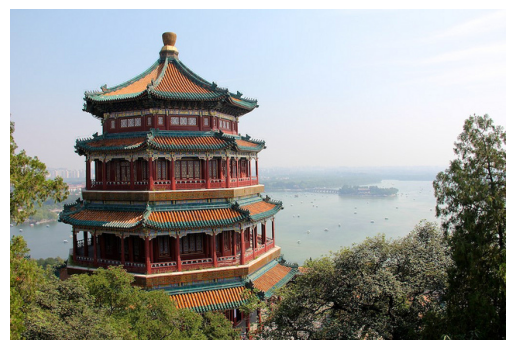

In [98]:
images = load_sample_images()['images']

plt.imshow(images[0])
plt.axis('off')
plt.show()

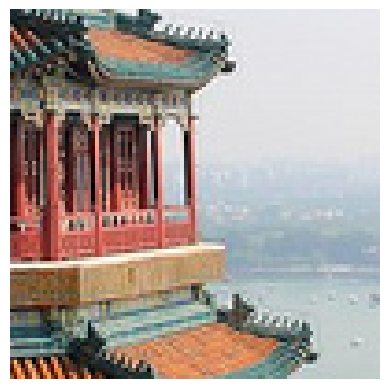

In [99]:
crop_image_layer = tf.keras.layers.CenterCrop(height=100, width=100)
cropped_images = crop_image_layer(images)
plt.imshow(cropped_images[0] / 255)
plt.axis('off')
plt.show()

## 13.4 텐서플로 데이터셋 프로젝트

In [100]:
import tensorflow_datasets as tfds

dataset = tfds.load(name='mnist')
mnist_train, mnist_test = dataset['train'], dataset['test']

In [101]:
for batch in mnist_train.shuffle(10_000, seed=42).batch(32).prefetch(1):
    images = batch['image']
    labels = batch['label']
    # [...] images와 labels로 무언가를 수행

In [102]:
mnist_train.take(1)

<_TakeDataset element_spec={'image': TensorSpec(shape=(28, 28, 1), dtype=tf.uint8, name=None), 'label': TensorSpec(shape=(), dtype=tf.int64, name=None)}>

In [103]:
mnist_train = mnist_train.shuffle(10_000, seed=42).batch(32)
mnist_train = mnist_train.map(lambda items: (items['image'], items['label']))
mnist_train = mnist_train.prefetch(1)

mnist_train.take(1)

<_TakeDataset element_spec=(TensorSpec(shape=(None, 28, 28, 1), dtype=tf.uint8, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>

In [104]:
dataset = tfds.load(name='mnist', as_supervised=True)
mnist_train, minst_test = dataset['train'], dataset['test']
mnist_train = mnist_train.shuffle(10_000, seed=42).batch(1).prefetch(1)

mnist_train.take(1)

<_TakeDataset element_spec=(TensorSpec(shape=(None, 28, 28, 1), dtype=tf.uint8, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>

In [105]:
dataset = tfds.load(name='mnist', split=['train[:90%]', 'train[90%:]', 'test'])
dataset

[<_PrefetchDataset element_spec={'image': TensorSpec(shape=(28, 28, 1), dtype=tf.uint8, name=None), 'label': TensorSpec(shape=(), dtype=tf.int64, name=None)}>,
 <_PrefetchDataset element_spec={'image': TensorSpec(shape=(28, 28, 1), dtype=tf.uint8, name=None), 'label': TensorSpec(shape=(), dtype=tf.int64, name=None)}>,
 <_PrefetchDataset element_spec={'image': TensorSpec(shape=(28, 28, 1), dtype=tf.uint8, name=None), 'label': TensorSpec(shape=(), dtype=tf.int64, name=None)}>]

In [106]:
len(dataset[0]), len(dataset[1]), len(dataset[2])

(54000, 6000, 10000)

In [107]:
train_set, valid_set, test_set = tfds.load(
    name='mnist', split=['train[:90%]', 'train[90%:]', 'test'], as_supervised=True)

train_set = train_set.shuffle(10_000, seed=42).batch(32).prefetch(1)
valid_set = valid_set.batch(32).cache()
test_set = test_set.batch(32).cache()

In [108]:
tf.random.set_seed(42)

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(10, activation='softmax')
])
model.compile(loss='sparse_categorical_crossentropy', optimizer='nadam',
              metrics=['accuracy'])
history = model.fit(train_set, validation_data=valid_set, epochs=5)

test_loss, test_accuracy = model.evaluate(test_set)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 1s 558us/step - accuracy: 0.8304 - loss: 10.5918 - val_accuracy: 0.8625 - val_loss: 7.1451
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 1s 416us/step - accuracy: 0.8789 - loss: 5.6497 - val_accuracy: 0.8820 - val_loss: 5.5792
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 1s 414us/step - accuracy: 0.8826 - loss: 5.2260 - val_accuracy: 0.8885 - val_loss: 5.5798
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 1s 414us/step - accuracy: 0.8857 - loss: 5.0883 - val_accuracy: 0.8907 - val_loss: 5.6226
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 1s 416us/step - accuracy: 0.8866 - loss: 4.9291 - val_accuracy: 0.8610 - val_loss: 7.3180
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 407us/step - accuracy: 0.8544 - loss: 7.3199


## 연습문제

### ⑨

In [109]:
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

X_train, X_valid = X_train_full[5000:], X_train_full[:5000]
y_train, y_valid = y_train_full[5000:], y_train_full[:5000]

In [110]:
train_set = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_set = train_set.shuffle(len(train_set), seed=42)
valid_set = tf.data.Dataset.from_tensor_slices((X_valid, y_valid))
test_set = tf.data.Dataset.from_tensor_slices((X_test, y_test))

In [111]:
def create_example(image, label):
    image_data = tf.io.serialize_tensor(image)
    return Example(
        features=Features(
            feature={
                'iamge': Feature(bytes_list=BytesList(value=[image_data.numpy()])),
                'label': Feature(int64_list=Int64List(value=[label]))
            }
        )
    )

In [112]:
for image, label in train_set.take(1):
    print(create_example(image, label))

features {
  feature {
    key: "label"
    value {
      int64_list {
        value: 4
      }
    }
  }
  feature {
    key: "iamge"
    value {
      bytes_list {
        value: "\010\004\022\010\022\002\010\034\022\002\010\034\"\220\006\000\000\000\000\000\000\000\000\000\000T\301\206Wi\\\217\203\000\000\001\000\000\000\000\000\000\000\000\000\000\000\000\000\000\000\006\350\343\325\363\377\377\356\351\362\305\000\000\000\000\000\000\000\000\000\000\000\000\000\000\000\000\000\262\366\276\316\353\340\351\362\321\277\337\234\027\000\000\002\000\000\000\000\000\000\000\000\000\000\000e\327\320\320\312\363\361\357\366\326\330\327\327\333c\000\000\000\000\000\000\000\000\000\000\000\000B\334\312\327\351\327\337\372\373\357\335\324\312\311\312\316\007\000\002\000\000\000\000\000\000\000\000\000\276\314\301\315\311\315\326\330\335\312\310\310\313\312\302\326W\000\002\000\000\000\000\000\000\000\000Z\333\305\300\271\300\301\277\276\275\276\262\247\271\274\301\323\251\000\000\000\000\000\0

In [113]:
for image, label in train_set.take(1):
    print(create_example(image, label).SerializeToString())

b'\n\xc2\x06\n\xaf\x06\n\x05iamge\x12\xa5\x06\n\xa2\x06\n\x9f\x06\x08\x04\x12\x08\x12\x02\x08\x1c\x12\x02\x08\x1c"\x90\x06\x00\x00\x00\x00\x00\x00\x00\x00\x00nqQY[bfn\x82i\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\xf4\xda\xd2\xdc\xc8\xc5\xed\xcb\xde\xf8\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x08\xc6\xa5\xbc\xc0\xbf\xc6\xce\xab\xb9\xea\x11\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x009\xda\xcb\xd3\xd3\xbb\xb6\xd0\xd4\xcb\xedM\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00l\xe5\xc1\xc1\xc9\xc3\xc8\xd1\xcc\xbf\xdfU\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x9d\xd1\xbe\xc8\xc9\xc9\xcf\xce\xc5\xbb\xdd\x8f\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\xa7\xcb\xbd\xbf\xc9\xbb\xc1\xd2\xc9\xc3\xd3\xaa\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\xa8\xd0\xbf\xc7\xc8\xc5\xcb\xce\xc5\xbd\xca\xb4\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\

In [114]:
train_set = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_set = train_set.shuffle(len(train_set), seed=42).batch(32).prefetch(1)
valid_set = tf.data.Dataset.from_tensor_slices((X_valid, y_valid)).batch(32).prefetch(1)
test_set = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(32).prefetch(1)

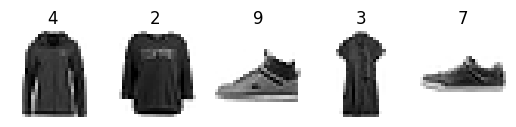

In [115]:
for X, y in train_set.take(1):
    for i in range(5):
        plt.subplot(1, 5, i + 1)
        plt.imshow(np.array(X[i]), cmap='binary')
        plt.title(y[i].numpy())
        plt.axis('off')
        
plt.show()

In [116]:
tf.random.set_seed(42)

normalization_layer = tf.keras.layers.Normalization(axis=(1, 2))
normalization_layer.adapt(train_set.take(1000).map(lambda image, label: image))

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    normalization_layer,
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])
model.compile(loss='sparse_categorical_crossentropy', optimizer='nadam', metrics=['accuracy'])
history = model.fit(train_set, epochs=5, validation_data=valid_set)

Epoch 1/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 889us/step - accuracy: 0.8417 - loss: 0.4492 - val_accuracy: 0.8750 - val_loss: 0.3705
Epoch 2/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 860us/step - accuracy: 0.8800 - loss: 0.3341 - val_accuracy: 0.8766 - val_loss: 0.3559
Epoch 3/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 859us/step - accuracy: 0.8917 - loss: 0.2974 - val_accuracy: 0.8716 - val_loss: 0.3744
Epoch 4/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 858us/step - accuracy: 0.9017 - loss: 0.2688 - val_accuracy: 0.8752 - val_loss: 0.3579
Epoch 5/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 858us/step - accuracy: 0.9074 - loss: 0.2513 - val_accuracy: 0.8836 - val_loss: 0.3493


In [117]:
model.evaluate(test_set)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 436us/step - accuracy: 0.8731 - loss: 0.3704


[0.37036585807800293, 0.8730999827384949]

### ⑩

#### Step A

In [118]:
from pathlib import Path

root = 'https://ai.stanford.edu/~amaas/data/sentiment/'
filename = 'aclImdb_v1.tar.gz'
filepath = tf.keras.utils.get_file(filename, root + filename, extract=True, cache_dir=".")
if '_extracted' in filepath:
    path = Path(filepath) / 'aclImdb'
else:
    path = Path(filepath).with_name('aclImdb')

In [119]:
def review_paths(dirpath):
    return [str(path) for path in dirpath.glob('*.txt')]

train_pos = review_paths(path / 'train' / 'pos')
train_neg = review_paths(path / 'train' / 'neg')
test_valid_pos = review_paths(path / 'test' / 'pos')
test_valid_neg = review_paths(path / 'test' / 'neg')

In [120]:
len(train_pos), len(train_neg), len(test_valid_pos), len(test_valid_neg)

(12500, 12500, 12500, 12500)

#### Step B

In [121]:
test_pos = test_valid_pos[:5000]
test_neg = test_valid_neg[:5000]
valid_pos = test_valid_pos[5000:]
valid_neg = test_valid_neg[5000:]

#### Step C

In [122]:
def create_dataset(filepaths_pos, filepaths_neg):
    reviews = []
    labels = []
    for filepaths, label in ((filepaths_pos, 1), (filepaths_neg, 0)):
        for filepath in filepaths:
            with open(filepath) as review_file:
                reviews.append(review_file.read())
            labels.append(label)

    return tf.data.Dataset.from_tensor_slices((reviews, labels))

In [123]:
for review, label in create_dataset(test_pos, test_neg).take(3):
    print(review)
    print(label)
    print()

tf.Tensor(b'Based on an actual story, John Boorman shows the struggle of an American doctor, whose husband and son were murdered and she was continually plagued with her loss. A holiday to Burma with her sister seemed like a good idea to get away from it all, but when her passport was stolen in Rangoon, she could not leave the country with her sister, and was forced to stay back until she could get I.D. papers from the American embassy. To fill in a day before she could fly out, she took a trip into the countryside with a tour guide. "I tried finding something in those stone statues, but nothing stirred in me. I was stone myself." <br /><br />Suddenly all hell broke loose and she was caught in a political revolt. Just when it looked like she had escaped and safely boarded a train, she saw her tour guide get beaten and shot. In a split second she decided to jump from the moving train and try to rescue him, with no thought of herself. Continually her life was in danger. <br /><br />Here 

In [124]:
batch_size = 32

train_set = create_dataset(train_pos, train_neg).shuffle(25_000, seed=42)
train_set = train_set.batch(batch_size).prefetch(1)
valid_set = create_dataset(valid_pos, valid_neg).batch(batch_size).prefetch(1)
test_set = create_dataset(test_pos, test_neg).batch(batch_size).prefetch(1)

#### Step D

In [125]:
max_tokens = 1000
sample_reviews = train_set.map(lambda review, label: review)
text_vectorization = tf.keras.layers.TextVectorization(max_tokens, output_mode='tf_idf')
text_vectorization.adapt(sample_reviews)

In [126]:
text_vectorization.get_vocabulary()[:10]

['[UNK]',
 np.str_('the'),
 np.str_('and'),
 np.str_('a'),
 np.str_('of'),
 np.str_('to'),
 np.str_('is'),
 np.str_('in'),
 np.str_('it'),
 np.str_('i')]

In [127]:
tf.keras.utils.set_random_seed(42)

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(), dtype=tf.string),
    text_vectorization,
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])
model.compile(loss='binary_crossentropy', optimizer='nadam', metrics=['accuracy'])
history = model.fit(train_set, epochs=5, validation_data=valid_set)

Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8202 - loss: 0.4343 - val_accuracy: 0.8491 - val_loss: 0.3684
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8552 - loss: 0.3570 - val_accuracy: 0.8552 - val_loss: 0.3527
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8709 - loss: 0.3178 - val_accuracy: 0.8505 - val_loss: 0.3586
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8930 - loss: 0.2617 - val_accuracy: 0.8510 - val_loss: 0.3546
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9210 - loss: 0.1973 - val_accuracy: 0.8498 - val_loss: 0.3872


#### Step E

In [128]:
def compute_mean_embedding(inputs):
    not_pad = tf.math.count_nonzero(inputs, axis=-1)                   # (batch, seq_len)
    n_words = tf.math.count_nonzero(not_pad, axis=-1, keepdims=True)   # (batch, 1)
    sqrt_n_words = tf.math.sqrt(tf.cast(n_words, tf.float32))          # (batch, 1)
    return tf.reduce_sum(inputs, axis=1) / sqrt_n_words

In [129]:
tf.keras.utils.set_random_seed(42)

embedding_size = 20
text_vectorization = tf.keras.layers.TextVectorization(max_tokens, output_mode='int')
text_vectorization.adapt(sample_reviews)

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(), dtype=tf.string),
    text_vectorization,
    tf.keras.layers.Embedding(input_dim=max_tokens, output_dim=embedding_size),
    tf.keras.layers.Lambda(compute_mean_embedding),
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

#### Step F

In [130]:
model.compile(loss='binary_crossentropy', optimizer='nadam', metrics=['accuracy'])
history = model.fit(train_set, epochs=5, validation_data=valid_set)

Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.6262 - loss: 0.6326 - val_accuracy: 0.7456 - val_loss: 0.5269
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7561 - loss: 0.5053 - val_accuracy: 0.7439 - val_loss: 0.4815
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7870 - loss: 0.4638 - val_accuracy: 0.8471 - val_loss: 0.4008
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8070 - loss: 0.4320 - val_accuracy: 0.6697 - val_loss: 0.7283
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8187 - loss: 0.4102 - val_accuracy: 0.7277 - val_loss: 0.5533


#### Step G

In [131]:
datasets = tfds.load(name='imdb_reviews')
train_set, test_set = datasets['train'], datasets['test']

In [132]:
for example in train_set.take(1):
    print(example['text'])
    print(example['label'])

tf.Tensor(b"This was an absolutely terrible movie. Don't be lured in by Christopher Walken or Michael Ironside. Both are great actors, but this must simply be their worst role in history. Even their great acting could not redeem this movie's ridiculous storyline. This movie is an early nineties US propaganda piece. The most pathetic scenes were those when the Columbian rebels were making their cases for revolutions. Maria Conchita Alonso appeared phony, and her pseudo-love affair with Walken was nothing but a pathetic emotional plug in a movie that was devoid of any real meaning. I am disappointed that there are movies like this, ruining actor's like Christopher Walken's good name. I could barely sit through it.", shape=(), dtype=string)
tf.Tensor(0, shape=(), dtype=int64)
